# Flagship 2 — Jordà-style local projections

Exploratory horizon-specific growth-response regressions using observed monthly Brent returns and sector YoY growth. They are associations, NOT identified causal impulses.

**Real data only.** Run ingestion first. Never interpret an empty or skipped model as a finding.

In [1]:
from pathlib import Path
import sys
for loc in [Path.cwd(),Path.cwd()/'notebooks',Path.cwd()/'research_expansion'/'notebooks']:
    if (loc/'common.py').exists():
        sys.path.insert(0,str(loc.resolve()));break
from common import root, load_panel, load_cases, output

Saved C:\Users\mehak\OneDrive\ドキュメント\ChatGPT\Industry Res\reports\research\models\dynamic_response.json


,horizon_months,coef,standard_error,ci95_low,ci95_high,p_value,n_rows,n_unique_months
0,0,0.052831,0.149647,-0.240471,0.346133,0.724059,4840,165
1,3,0.468459,0.344124,-0.206010,1.142929,0.173415,4750,162
2,6,-0.030237,0.070548,-0.168508,0.108034,0.668210,4660,159
3,9,0.312740,0.290110,-0.255866,0.881346,0.281032,4570,156
4,12,-2.001982,1.822531,-5.574078,1.570114,0.272003,4480,153


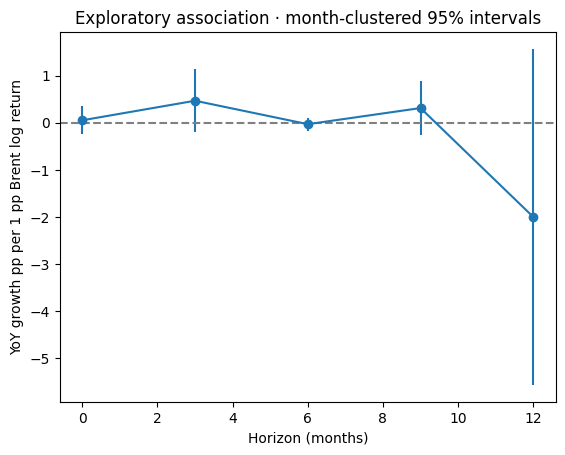

In [2]:
import numpy as np,pandas as pd
import statsmodels.formula.api as smf
p=load_panel().copy()
p['group']=p['country']+'_'+p['industry_code']
energy=p[['date','brent_usd']].dropna().groupby('date',as_index=False).agg(brent_usd=('brent_usd','median')).sort_values('date')
energy['oil_change_pct']=100*np.log(energy['brent_usd']/energy['brent_usd'].shift(1))
p=p.drop(columns=['brent_usd']).merge(energy[['date','oil_change_pct']],on='date',how='left')
p=p.sort_values(['group','date']);p['lag_growth']=p.groupby('group')['production_yoy_pct'].shift(1)
if p['date'].nunique()<100 or p['group'].nunique()<6:
    output('dynamic_response',{'status':'skipped','reason':'Need >=100 observed months and >=6 industry-country groups'})
else:
    records=[]
    for h in [0,3,6,9,12]:
        q=p.copy();q['future_yoy']=q.groupby('group')['production_yoy_pct'].shift(-h)
        q=q.dropna(subset=['future_yoy','oil_change_pct','lag_growth'])
        if q.date.nunique()<100 or q['group'].nunique()<6:continue
        # Brent return is common across groups: cluster uncertainty at calendar-month level.
        fit=smf.ols('future_yoy ~ oil_change_pct + lag_growth + C(group)',data=q).fit(
            cov_type='cluster',cov_kwds={'groups':q['date'].factorize()[0]})
        ci=fit.conf_int().loc['oil_change_pct'].tolist()
        records.append(dict(horizon_months=h,coef=fit.params['oil_change_pct'],
            standard_error=fit.bse['oil_change_pct'],ci95_low=ci[0],ci95_high=ci[1],
            p_value=fit.pvalues['oil_change_pct'],n_rows=len(q),n_unique_months=q.date.nunique()))
    output('dynamic_response',{'model':'Jorda-style exploratory local projections','status':'fitted' if records else 'skipped',
    'coefficients':records,'limitation':'Unidentified association; oil price mixes supply and demand origins; omitted macro confounding; overlapping YoY growth; not a firm survival prediction.'})
    display(pd.DataFrame(records))
    if records:
        import matplotlib.pyplot as plt
        chart=pd.DataFrame(records)
        plt.errorbar(chart.horizon_months, chart.coef,
                     yerr=[chart.coef-chart.ci95_low,chart.ci95_high-chart.coef],fmt='o-')
        plt.axhline(0,color='gray',linestyle='--')
        plt.xlabel('Horizon (months)')
        plt.ylabel('YoY growth pp per 1 pp Brent log return')
        plt.title('Exploratory association · month-clustered 95% intervals')
        plt.show()